## Can we show that the Yasso 800 workout is actually just an approximation of the well-studied speed vs distance curve?

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import altair as alt

/usr/local/lib/python3.6/site-packages/matplotlib/style/core.py:167: UserWarning: In /Users/andyreagan/.matplotlib/stylelib/paper-twocol.mplstyle: 
The text.latex.unicode rcparam was deprecated in Matplotlib 2.2 and will be removed in 3.1.
  styles = read_style_directory(stylelib_path)
/usr/local/lib/python3.6/site-packages/matplotlib/style/core.py:167: UserWarning: In /Users/andyreagan/.matplotlib/stylelib/paper-onecol.mplstyle: 
The text.latex.unicode rcparam was deprecated in Matplotlib 2.2 and will be removed in 3.1.
  styles = read_style_directory(stylelib_path)


In [2]:
x = np.linspace(0,30,100)

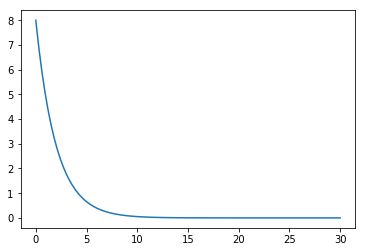

In [3]:
plt.plot(x, 8*np.exp(-.5*x))

In [4]:
26.2/.5

52.4

In [5]:
60/52.4

1.1450381679389314

In [6]:
52.4/60

0.8733333333333333

In [7]:
np.log(52.4/60)

-0.13543797089510426

In [8]:
np.log((26.2/.5)/60)

-0.13543797089510426

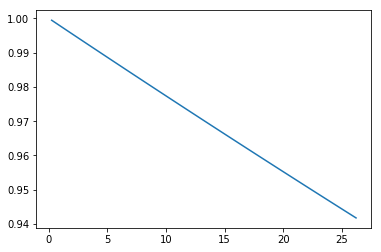

In [9]:
x = np.linspace(0.25,26.2,100)
k3 = 0.0022887
plt.plot(x, np.exp(-k3*x))

In [10]:
k3 = (60/(26.2/0.5))/((26.2-0.5))
k3

0.04455401431668994

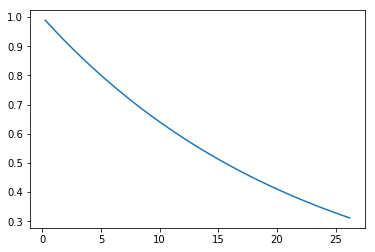

In [11]:
x = np.linspace(0.25,26.2,100)
plt.plot(x, np.exp(-k3*x))

In [12]:
k = np.log( 26.2 / (60 * 0.5) ) / (- ( 26.2 - 0.5 ) )
k

0.005269959957007948

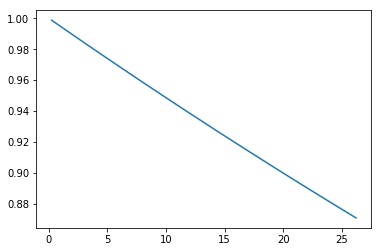

In [13]:
x = np.linspace(0.25,26.2,100)
plt.plot(x, np.exp(-k*x))

## Look at how world record performances fit on this curve

World record performances are here on [Wikipedia](https://en.wikipedia.org/wiki/List_of_world_records_in_athletics#Men)

Convert to CSV using [this webpage](https://wikitable2csv.ggor.de/) and process out the records in the notebook `process_wikipedia_data`.

In [3]:
mens_running_all_dedup = pd.read_pickle("data/mens_running_all_dedup.pkl")
mens_running_all_dedup_nondecreasing = pd.read_pickle("data/mens_running_all_dedup_nondecreasing.pkl")
mens_running_all_dedup_nondecreasing_aerobic = pd.read_pickle("data/mens_running_all_dedup_nondecreasing_aerobic.pkl")

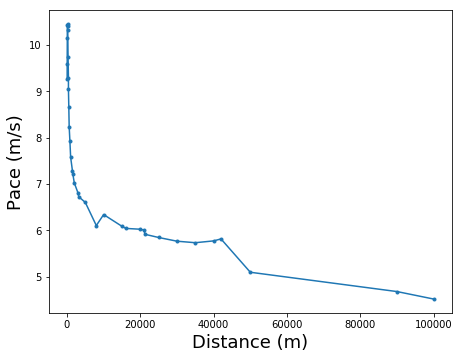

In [34]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_axes([0.2, 0.2, 0.7, 0.7])
ax.plot(mens_running_all_dedup.distance, mens_running_all_dedup.pace, '.-')
ax.set_xlabel("Distance (m)", fontsize=18,)
ax.set_ylabel("Pace (m/s)", fontsize=18,)
# ax.set_yticklabels(ax.get_yticklabels(), fontsize=20,)
plt.savefig("all-running-dedup.png", dpi=300, bbox_inches="tight")

In [35]:
alt.Chart(mens_running_all_dedup).mark_line().encode(x="distance", y="pace")

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


In [36]:
line = (alt.Chart(mens_running_all_dedup)
  .mark_line()
  .encode(x=alt.X("distance:Q"), 
          y=alt.Y("pace:Q")
         )
  .properties(
      title='Distance vs Pace'
  )
)

circle = (alt.Chart(mens_running_all_dedup)
  .mark_circle()
  .encode(x=alt.X("distance:Q"), 
          y=alt.Y("pace:Q"),
          tooltip=["Event", "Athlete", "Perf"]
         )
  .properties(
      title='Distance vs Pace'
  ).interactive()
)

line.encoding.x.title = 'Distance (m)'
line.encoding.y.title = 'Pace (m/s)'

line + circle

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


In [37]:
line = (alt.Chart(mens_running_all_dedup)
  .mark_line()
  .encode(x=alt.X("logdistance:Q"), 
          y=alt.Y("logpace:Q")
         )
  .properties(
      title='Log10(Distance) vs Log10(Pace)'
  )
)

circle = (alt.Chart(mens_running_all_dedup)
  .mark_circle()
  .encode(x=alt.X("logdistance:Q"), 
          y=alt.Y("logpace:Q"),
          tooltip=["Event", "Athlete", "Perf"]
         )
  .properties(
      title='Log10(Distance) vs Log10(Pace)'
  ).interactive()
)

line.encoding.x.title = 'Log10( Distance (m) )'
line.encoding.y.title = 'Log10( Pace (m/s) )'

line + circle

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


In [44]:
line = (alt.Chart(mens_running_all_dedup_nondecreasing)
  .mark_line()
  .encode(x=alt.X("distance:Q"), 
          y=alt.Y("pace:Q")
         )
  .properties(
      title='Distance vs Pace'
  )
)

circle = (alt.Chart(mens_running_all_dedup_nondecreasing)
  .mark_circle()
  .encode(x=alt.X("distance:Q"), 
          y=alt.Y("pace:Q"),
          tooltip=["Event", "Athlete", "Perf"]
         )
  .properties(
      title='Distance vs Pace'
  ).interactive()
)

line.encoding.x.title = 'Distance (m)'
line.encoding.y.title = 'Pace (m/s)'

line + circle

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


In [45]:
line = (alt.Chart(mens_running_all_dedup_nondecreasing)
  .mark_line()
  .encode(x=alt.X("distance:Q"), 
          y=alt.Y("logpace:Q")
         )
  .properties(
      title='Distance vs Log10( Pace )'
  )
)

circle = (alt.Chart(mens_running_all_dedup_nondecreasing)
  .mark_circle()
  .encode(x=alt.X("distance:Q"), 
          y=alt.Y("logpace:Q"),
          tooltip=["Event", "Athlete", "Perf"]
         )
  .properties(
      title='Distance vs Log10( Pace )'
  ).interactive()
)

line.encoding.x.title = 'Distance (m)'
line.encoding.y.title = 'Log10( Pace (m/s) )'

line + circle

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


In [46]:
line = (alt.Chart(mens_running_all_dedup_nondecreasing)
  .mark_line()
  .encode(x=alt.X("logdistance:Q"), 
          y=alt.Y("pace:Q")
         )
  .properties(
      title='Log10(Distance) vs Pace'
  )
)

circle = (alt.Chart(mens_running_all_dedup_nondecreasing)
  .mark_circle()
  .encode(x=alt.X("logdistance:Q"), 
          y=alt.Y("pace:Q"),
          tooltip=["Event", "Athlete", "Perf"]
         )
  .properties(
      title='Log10(Distance) vs Pace'
  ).interactive()
)

line.encoding.x.title = 'Log10( Distance (m) )'
line.encoding.y.title = 'Pace (m/s)'

line + circle

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


In [47]:
line = (alt.Chart(mens_running_all_dedup_nondecreasing)
  .mark_line()
  .encode(x=alt.X("logdistance:Q"), 
          y=alt.Y("logpace:Q")
         )
  .properties(
      title='Log10(Distance) vs Log10(Pace)'
  )
)

circle = (alt.Chart(mens_running_all_dedup_nondecreasing)
  .mark_circle()
  .encode(x=alt.X("logdistance:Q"), 
          y=alt.Y("logpace:Q"),
          tooltip=["Event", "Athlete", "Perf"]
         )
  .properties(
      title='Log10(Distance) vs Log10(Pace)'
  ).interactive()
)

line.encoding.x.title = 'Log10( Distance (m) )'
line.encoding.y.title = 'Log10( Pace (m/s) )'

line + circle

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


In [ ]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_axes([0.2, 0.2, 0.7, 0.7])
ax.plot(np.log10(mens_running_all_dedup.distance), np.log10(mens_running_all_dedup.pace), 'r.')
ax.plot(np.log10(mens_running_all_dedup_nondecreasing.distance), np.log10(mens_running_all_dedup_nondecreasing.pace), '.-')
ax.set_xlabel("Log10(Distance) (m)", fontsize=18,)
ax.set_ylabel("Log10(Pace) (m/s)", fontsize=18,)
# ax.set_yticklabels(ax.get_yticklabels(), fontsize=20,)
plt.savefig("all-running-dedup-loglog.png", dpi=300, bbox_inches="tight")

# Build a model for world record performances

In [50]:
import statsmodels.formula.api as smf

In [51]:
results = smf.ols('logpace ~ logdistance', data=mens_running_all_dedup_nondecreasing).fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                logpace   R-squared:                       0.959
Model:                            OLS   Adj. R-squared:                  0.957
Method:                 Least Squares   F-statistic:                     577.8
Date:                Sat, 17 Aug 2019   Prob (F-statistic):           8.49e-19
Time:                        11:28:14   Log-Likelihood:                 66.422
No. Observations:                  27   AIC:                            -128.8
Df Residuals:                      25   BIC:                            -126.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       1.2517      0.017     72.414      0.000       1.216       1.287
logdistance    -0.1144      0.005    -24.038      0.000      -0.124      -0.105
==============================================================================
Omnibus:                        6.215   Durbin-Watson:                   0.387
Prob(Omnibus):                  0.045   Jarque-Bera (JB):                1.886
Skew:                           0.087   Prob(JB):                        0.390
Kurtosis:                       1.717   Cond. No.                         16.3
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [52]:
model = [results.params.Intercept, results.params.logdistance]
# model = [1.16, -.08]

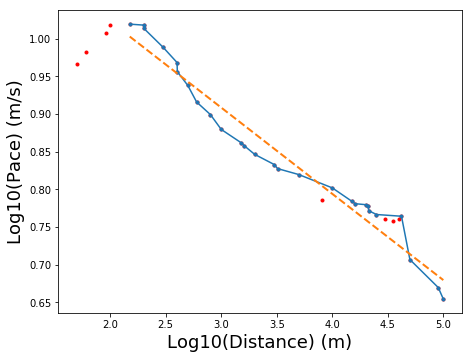

In [53]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_axes([0.2, 0.2, 0.7, 0.7])
ax.plot(np.log10(mens_running_all_dedup.distance), np.log10(mens_running_all_dedup.pace), 'r.')
ax.plot(np.log10(mens_running_all_dedup_nondecreasing.distance), np.log10(mens_running_all_dedup_nondecreasing.pace), '.-')
x = np.log10(mens_running_all_dedup_nondecreasing.distance)
y = model[0] + model[1] * x
ax.plot(x, y, '--', linewidth=2)
ax.set_xlabel("Log10(Distance) (m)", fontsize=18,)
ax.set_ylabel("Log10(Pace) (m/s)", fontsize=18,)
# ax.set_yticklabels(ax.get_yticklabels(), fontsize=20,)
plt.savefig("all-running-dedup-loglog-fit.png", dpi=300, bbox_inches="tight")

## Pace as power law

We are saying that

$$ pace = b \cdot distance^{a} $$

which we fit by taking the log of both sides

$$ \log _{10} pace = \log _{10}  distance ^{a}  + \log _{10} b = a \log _{10}  distance  + \log _{10} b$$

so in this case, the fitted $ b ^ * = \log _{10} b$, or since we care about $b$, we can say that $ b = 10 ^{b^*} $.

This gives us the fitted equation (with $b^* = 1.2517$) of

$$ pace = 17.85 \cdot distance ^ {-0.1144} $$.

The Yasso adjustment then is just:

In [56]:
17.85 * ( 42000. ** (-0.1144) ) / (17.85 * ( (5*1609) ** (-0.1144) ))

0.8277371761874259

In [70]:
17.85 * ( 42000. ** (-0.1144) ) / (17.85 * ( (3*1609) ** (-0.1144) ))

0.7807517460801028

s = 9.43 t ^ (0.938-1)

In [83]:
9.43**(-.938)

0.12187314885599644

In [84]:
0.1218 * (5000 ** (-.938))

4.130602696638494e-05

d = 9.43 t ^ (0.938)

log(d) = log(9.43) + .938 log(t)

log(t) = (log(d) - log(9.43))/.938

or log(t) = log((d/9.43)^-.938)

log(t) - log(d) = (log(d) - log(9.43))/.938 - log(d)

log(t/d) = (log(d) - log(9.43))/.938 - log(d)

s = e ^ ((log(d) - log(9.43))/.938 - log(d))

t = 0.1218 * d ^ (-.938)



In [82]:
d = 42000
s2 = np.exp(((np.log(d/9.43))/.938 - np.log(d)))
d = 5*1609
s1 =  np.exp(((np.log(d/9.43))/.938 - np.log(d)))

0.896519769918981

## Pace as exponential on distance

So we can say that we have

$$ pace = a e^{b * distance} $$

which we fit as

$$ log(pace) = log(a) + b * distance $$



In [71]:
results = smf.ols('logpace ~ distance', data=mens_running_all_dedup_nondecreasing).fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                logpace   R-squared:                       0.600
Model:                            OLS   Adj. R-squared:                  0.584
Method:                 Least Squares   F-statistic:                     37.48
Date:                Sat, 17 Aug 2019   Prob (F-statistic):           2.12e-06
Time:                        11:50:47   Log-Likelihood:                 35.821
No. Observations:                  27   AIC:                            -67.64
Df Residuals:                      25   BIC:                            -65.05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.8968      0.015     59.411      0.000       0.866       0.928
distance   -3.042e-06   4.97e-07     -6.122      0.000   -4.07e-06   -2.02e-06
==============================================================================
Omnibus:                        4.570   Durbin-Watson:                   0.128
Prob(Omnibus):                  0.102   Jarque-Bera (JB):                3.069
Skew:                           0.656   Prob(JB):                        0.216
Kurtosis:                       1.997   Cond. No.                     3.57e+04
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.57e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [72]:
np.exp(0.8968)

2.4517449609472033

so our fit model says

$$ pace(m/s) = 2.45 e ^{-3.042e-06 * distance(m)} $$

In [57]:
results.predict(mens_running_all_dedup_nondecreasing.distance)

7     0.896388
1     0.896236
9     0.896232
11    0.895931
2     0.895627
12    0.895620
13    0.895323
14    0.895019
3     0.894410
4     0.893802
5     0.892281
6     0.891950
7     0.890760
8     0.887718
15    0.887055
9     0.881634
12    0.866424
18    0.851214
19    0.847898
20    0.836004
16    0.832962
17    0.832095
21    0.820794
21    0.769080
25    0.744744
26    0.623064
22    0.592644
dtype: float64

In [58]:
records = alt.Chart(mens_running_all_dedup_nondecreasing).mark_line().encode(x="distance", y="logpace")
mens_running_all_dedup_nondecreasing["predicted"] = results.predict(mens_running_all_dedup_nondecreasing.distance)
predictions = alt.Chart(mens_running_all_dedup_nondecreasing).mark_line().encode(x="distance", y="predicted", color="red:N")

records + predictions

/usr/local/lib/python3.6/site-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  


<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


In [59]:
records = alt.Chart(mens_running_all_dedup_nondecreasing).mark_line().encode(x="distance", y="pace")
mens_running_all_dedup_nondecreasing["predicted"] = 10**results.predict(mens_running_all_dedup_nondecreasing.distance)
predictions = alt.Chart(mens_running_all_dedup_nondecreasing).mark_line().encode(x="distance", y="predicted", color="red:N")

records + predictions

/usr/local/lib/python3.6/site-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  


<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


## Is there a difference in using time as the `x`?

In [60]:
records = alt.Chart(mens_running_all_dedup_nondecreasing).mark_line().encode(x="seconds", y="pace", tooltip=["Event"]).interactive()

records

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


There are likely two regimes here: anerobic and aerobic.

In [61]:
records = alt.Chart(mens_running_all_dedup_nondecreasing).mark_line().encode(x="time", y="logpace")

records

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


## Energy systems

The graph above depicts two energy systems: aerobic and anaerobic.

In `references/gastin2001energy.pdf`, Figures 4 and 5, we see that the anaerobic system is depleted in a matter of minutes.
For longer form exercise, the maximal production from the anerobic system is limited.

A VO2max effort can be sustained for 5-8 minutes, and we focus on efforts starting at this length.
In this way, we are studying the aerobic system as the limiting factor in output.

We pull out all events longer than 300 seconds (5 minutes).

In [63]:
records = alt.Chart(mens_running_all_dedup_nondecreasing_aerobic).mark_line().encode(x="time", y="pace")

records

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


In [64]:
records = alt.Chart(mens_running_all_dedup_nondecreasing_aerobic).mark_line().encode(x="time", y="logpace")

records

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


In [65]:
results = smf.ols('logpace ~ time', data=mens_running_all_dedup_nondecreasing_aerobic).fit()
results.summary()

/usr/local/lib/python3.6/site-packages/scipy/stats/stats.py:1450: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=14
  "anyway, n=%i" % int(n))


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                logpace   R-squared:                       0.925
Model:                            OLS   Adj. R-squared:                  0.919
Method:                 Least Squares   F-statistic:                     148.6
Date:                Sat, 17 Aug 2019   Prob (F-statistic):           4.06e-08
Time:                        11:28:17   Log-Likelihood:                 39.559
No. Observations:                  14   AIC:                            -75.12
Df Residuals:                      12   BIC:                            -73.84
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.8118      0.006    146.850      0.000       0.800       0.824
time          -0.0005   3.77e-05    -12.191      0.000      -0.001      -0.000
==============================================================================
Omnibus:                        0.057   Durbin-Watson:                   1.206
Prob(Omnibus):                  0.972   Jarque-Bera (JB):                0.255
Skew:                          -0.106   Prob(JB):                        0.880
Kurtosis:                       2.374   Cond. No.                         196.
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [66]:
mens_running_all_dedup_nondecreasing_aerobic["predicted"]

8     7.721792
15    7.710010
9     7.614372
12    7.352315
18    7.099277
19    7.045281
20    6.854947
16    6.807100
17    6.793525
21    6.619027
21    5.875978
25    5.555769
26    4.198211
22    3.914212
Name: predicted, dtype: float64

In [67]:
results.predict(mens_running_all_dedup_nondecreasing.time)

7     0.811690
1     0.811653
9     0.811650
11    0.811564
2     0.811470
12    0.811459
13    0.811357
14    0.811242
3     0.811026
4     0.810788
5     0.810220
6     0.810089
7     0.809616
8     0.808420
15    0.808129
9     0.805992
12    0.799702
18    0.792896
19    0.791370
20    0.786331
16    0.784974
17    0.784192
21    0.778992
21    0.756391
25    0.736506
26    0.664180
22    0.641901
dtype: float64

In [68]:
mens_running_all_dedup_nondecreasing_aerobic["predicted"] = results.predict(mens_running_all_dedup_nondecreasing_aerobic.time)

/usr/local/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [69]:
records = alt.Chart(mens_running_all_dedup_nondecreasing_aerobic).mark_line().encode(x="time", y="logpace", tooltip="Event").interactive()
predictions = alt.Chart(mens_running_all_dedup_nondecreasing_aerobic).mark_line().encode(x="time", y="predicted", color="red:N")

records + predictions

<VegaLite 2 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/troubleshooting.html


It looks like we may even need to include a "fatigue" factor past the marathon distance. Kipchoge's effort really is off the chart, with such a focus on this specific distance.

This anamoly decreased when I fit logpace, the model we had intended with $pace = exp(-distance)$

# Fit for vandewalle's parameters

In [73]:
results = smf.ols('logdistance ~ logtime', data=mens_running_all_dedup_nondecreasing).fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            logdistance   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 5.483e+04
Date:                Sat, 17 Aug 2019   Prob (F-statistic):           2.71e-43
Time:                        11:54:23   Log-Likelihood:                 69.352
No. Observations:                  27   AIC:                            -134.7
Df Residuals:                      25   BIC:                            -132.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.7192      0.005    536.922      0.000       2.709       2.730
logtime        0.8969      0.004    234.166      0.000       0.889       0.905
==============================================================================
Omnibus:                        5.786   Durbin-Watson:                   0.387
Prob(Omnibus):                  0.055   Jarque-Bera (JB):                1.829
Skew:                           0.088   Prob(JB):                        0.401
Kurtosis:                       1.737   Cond. No.                         2.43
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [76]:
np.exp(2.7192)

15.168182843565921

## Look at this curve just for Haile?

https://en.wikipedia.org/wiki/Haile_Gebrselassie

# Ref

[Running calculator with references to other calculators](https://wismuth.com/running/calculator.html)
